In [1]:
import os
import time
import numpy as np
import pandas as pd

# Rutas de datos (mismo shard auditado en el Notebook 01)
raw_data_path = "../data/raw/train-00000-of-00037.parquet"
processed_dir = "../data/processed/modelo3"
os.makedirs(processed_dir, exist_ok=True)

print("📖 Cargando el shard completo de Hugging Face...")
columnas = ['variant', 'venue', 'day', 'time', 'hand', 'source_file', 'players',
            'starting_stacks', 'blinds_or_straddles', 'actions']
df_raw = pd.read_parquet(raw_data_path, columns=columnas)

# 1. Mismos filtros de calidad del Notebook 02
df_nt = df_raw[
    (df_raw['variant'] == 'NT') &
    (df_raw['venue'].isin(['Full Tilt Poker', 'Absolute Poker']))
].copy()

# 2. Nivel de apuestas: el nombre del archivo indica la mesa (50NL o 1000NL)
df_nt['nivel'] = df_nt['source_file'].str.extract(r'_(\d+NLH)')[0]
df_nt['stake_1000'] = (df_nt['nivel'] == '1000NLH').astype(int)

# 3. ORDEN CRONOLÓGICO: el perfil de cada jugador solo podrá usar manos anteriores
df_nt = df_nt.sort_values(['day', 'time', 'hand']).reset_index(drop=True)
df_nt['hand_key'] = np.arange(len(df_nt))

print(f"✅ Manos de calidad listas para reconstruir: {len(df_nt):,}")
print(f" • Días cubiertos: {int(df_nt['day'].min())} al {int(df_nt['day'].max())} de julio de 2009")
print("\n🃏 Manos por red y nivel de apuestas:")
for (red, nivel), n in df_nt.groupby(['venue', 'nivel']).size().items():
    print(f" • {red:<16} {nivel:<8}: {n:,} manos ({n / len(df_nt) * 100:.1f}%)")

📖 Cargando el shard completo de Hugging Face...


✅ Manos de calidad listas para reconstruir: 440,249
 • Días cubiertos: 1 al 20 de julio de 2009

🃏 Manos por red y nivel de apuestas:
 • Absolute Poker   1000NLH : 66,830 manos (15.2%)
 • Full Tilt Poker  50NLH   : 373,419 manos (84.8%)


In [2]:
# Cartas: valores numéricos para describir la textura de la mesa (información PÚBLICA)
RANKS = {r: i for i, r in enumerate('23456789TJQKA', start=2)}

def separar_cartas(texto):
    """Convierte 'Qs9c2h' en ['Qs', '9c', '2h']."""
    return [texto[i:i + 2] for i in range(0, len(texto), 2)]

def textura_mesa(board):
    """
    Describe las cartas comunitarias visibles en el momento de la decisión.
    Solo usa cartas ya repartidas: nunca cartas futuras (Doc. Maestro § 8.5).
    """
    if not board:
        return dict(b_n=0, b_pareada=0, b_trio=0, b_max_palo=0, b_alta=0, b_broadway=0, b_conect=0)
    valores = [RANKS[c[0]] for c in board]
    palos = [c[1] for c in board]
    repeticiones = np.bincount(valores, minlength=15)
    unicos = set(valores) | ({1} if 14 in valores else set())   # el As también cuenta como 1
    conectadas = max(sum(1 for k in range(lo, lo + 5) if k in unicos) for lo in range(1, 11))
    return dict(
        b_n=len(board),                                    # 0, 3, 4 o 5 cartas
        b_pareada=int(repeticiones.max() >= 2),            # mesa con pareja
        b_trio=int(repeticiones.max() >= 3),               # mesa con trío
        b_max_palo=max(palos.count(s) for s in set(palos)),# cartas del mismo palo (riesgo de color)
        b_alta=max(valores),                               # carta más alta
        b_broadway=sum(v >= 10 for v in valores),          # figuras (T, J, Q, K, A)
        b_conect=conectadas                                # cartas dentro de una ventana de escalera
    )

print("🧪 Prueba de la textura de mesa con un flop 'Qs 9s 2h':")
print("  ", textura_mesa(['Qs', '9s', '2h']))

🧪 Prueba de la textura de mesa con un flop 'Qs 9s 2h':
   {'b_n': 3, 'b_pareada': 0, 'b_trio': 0, 'b_max_palo': 2, 'b_alta': 12, 'b_broadway': 1, 'b_conect': 2}


In [3]:
class PerfilJugador:
    """
    Estadísticas tipo HUD de un jugador (como las que usan los profesionales en línea).
    REGLA ANTI-FUGA: se actualizan SOLO cuando termina una mano, así que una decisión
    nunca 've' su propia acción ni las acciones posteriores de esa misma mano.
    """
    def __init__(self):
        self.manos = 0
        self.vpip = 0        # manos en las que puso dinero voluntariamente preflop
        self.pfr = 0         # manos en las que subió preflop
        self.enfrenta = 0    # decisiones enfrentando una apuesta
        self.fold_enf = 0    # ... de ellas, cuántas se retiró
        self.raise_enf = 0   # ... de ellas, cuántas subió
        self.libre = 0       # decisiones sin apuesta que pagar
        self.bet_libre = 0   # ... de ellas, cuántas apostó
        self.post_dec = 0    # decisiones después del flop
        self.post_agr = 0    # ... de ellas, cuántas fueron agresivas

# Suavizado bayesiano: con pocas manos, el perfil se acerca al promedio de la población
PRIOR = {'vpip': (0.25, 10), 'pfr': (0.15, 10), 'fold_enf': (0.55, 10),
         'raise_enf': (0.12, 10), 'bet_libre': (0.35, 10), 'post_agr': (0.30, 10)}

def tasa(aciertos, intentos, clave):
    """(aciertos + prior * k) / (intentos + k): evita perfiles extremos con 1 o 2 manos."""
    p, k = PRIOR[clave]
    return (aciertos + p * k) / (intentos + k)

def variables_perfil(pf):
    if pf is None:   # jugador nunca visto: perfil promedio
        return dict(pf_manos=0.0, **{f"pf_{k}": v[0] for k, v in PRIOR.items()})
    return dict(
        pf_manos=np.log1p(pf.manos),
        pf_vpip=tasa(pf.vpip, pf.manos, 'vpip'),
        pf_pfr=tasa(pf.pfr, pf.manos, 'pfr'),
        pf_fold_enf=tasa(pf.fold_enf, pf.enfrenta, 'fold_enf'),
        pf_raise_enf=tasa(pf.raise_enf, pf.enfrenta, 'raise_enf'),
        pf_bet_libre=tasa(pf.bet_libre, pf.libre, 'bet_libre'),
        pf_post_agr=tasa(pf.post_agr, pf.post_dec, 'post_agr'),
    )

print("✅ Perfil de jugador definido. Ejemplo de jugador nuevo (perfil promedio):")
print("  ", {k: round(v, 3) for k, v in variables_perfil(None).items()})

✅ Perfil de jugador definido. Ejemplo de jugador nuevo (perfil promedio):
   {'pf_manos': 0.0, 'pf_vpip': 0.25, 'pf_pfr': 0.15, 'pf_fold_enf': 0.55, 'pf_raise_enf': 0.12, 'pf_bet_libre': 0.35, 'pf_post_agr': 0.3}


In [4]:
def reconstruir_decisiones_v3(mano, perfiles):
    """
    Versión 3 de la máquina de estados del Notebook 02.
    Mantiene la REGLA CLAVE (foto de la mesa SIEMPRE antes de actuar) y añade:
      • cantidades en ciegas grandes (comparables entre 50NL y 1000NL),
      • posición, jugadores activos e historial de apuestas de la ronda,
      • textura de la mesa y perfil histórico del jugador.
    Corrección adicional: en heads-up (2 jugadores) PHH lista las ciegas como [5, 10],
    pero quien pone la ciega pequeña es p2 (actúa primero preflop y último postflop).
    """
    decisiones = []
    n = len(mano.players)
    ciegas = [float(c) for c in mano.blinds_or_straddles]
    if n == 2:
        ciegas = ciegas[::-1]                      # p1 = ciega grande, p2 = ciega pequeña/botón
    bb = max(ciegas)
    if bb <= 0:
        return decisiones

    pids = [f"p{i+1}" for i in range(n)]
    nombre = dict(zip(pids, mano.players))
    stacks = {pids[i]: float(mano.starting_stacks[i]) for i in range(n)}
    inicial = dict(stacks)
    puesto = {p: 0.0 for p in pids}                # fichas puestas en la ronda actual
    bote, apuesta_alta = 0.0, 0.0
    for i, c in enumerate(ciegas):
        if c > 0:
            p = pids[i]; bote += c; stacks[p] -= c; puesto[p] = c; apuesta_alta = max(apuesta_alta, c)

    # Orden de actuación: preflop empieza el jugador tras la ciega grande; postflop la ciega pequeña
    if n == 2:
        orden_pre = {'p2': 0, 'p1': 1}
        orden_post = {'p1': 0, 'p2': 1}
    else:
        orden_pre = {p: (int(p[1:]) - 1 - 2) % n for p in pids}
        orden_post = {p: int(p[1:]) - 1 for p in pids}
    es_sb = {p: int(p == ('p2' if n == 2 else 'p1')) for p in pids}
    es_bb = {p: int(p == ('p1' if n == 2 else 'p2')) for p in pids}
    es_boton = {p: int(p == ('p2' if n == 2 else pids[-1])) for p in pids}

    activos = set(pids)
    calle, board = 0, []
    subidas_calle = callers_calle = checks_calle = subidas_pre = 0
    ultimo_agresor = agresor_prev = agresor_pre = None
    ult_apuesta = 0.0
    actuo_calle = {p: 0 for p in pids}
    subio_calle = {p: 0 for p in pids}
    acumulado = {p: dict(vpip=0, pfr=0, enfrenta=0, fold_enf=0, raise_enf=0, libre=0,
                         bet_libre=0, post_dec=0, post_agr=0) for p in pids}

    for act in mano.actions:
        partes = act.strip().split()
        if not partes:
            continue
        actor = partes[0]

        # A. El crupier reparte cartas comunitarias: nueva ronda
        if actor == 'd':
            if len(partes) >= 3 and partes[1] == 'db':
                calle += 1
                board += separar_cartas(partes[2])
                agresor_prev, ultimo_agresor = ultimo_agresor, None
                puesto = {p: 0.0 for p in pids}
                apuesta_alta = 0.0
                subidas_calle = callers_calle = checks_calle = 0
                ult_apuesta = 0.0
                actuo_calle = {p: 0 for p in pids}
                subio_calle = {p: 0 for p in pids}
            continue

        # B. Decide un jugador
        if len(partes) < 2 or partes[1] not in ('f', 'cc', 'cbr') or actor not in stacks:
            continue
        pid, tipo = actor, partes[1]

        # B1. FOTO DE LA MESA: todo se mide ANTES de que el jugador actúe
        to_call = max(0.0, apuesta_alta - puesto[pid])
        stack = stacks[pid]
        rivales = [stacks[q] + puesto[q] for q in activos if q != pid]
        efectivo = min(stack + puesto[pid], max(rivales)) if rivales else stack
        orden = orden_pre if calle == 0 else orden_post
        detras = sum(1 for q in activos if q != pid and stacks[q] > 0 and orden[q] > orden[pid])

        # B2. ETIQUETA (lo que hizo el jugador)
        label = {'f': 0, 'cc': 1, 'cbr': 2}[tipo]

        # B3. GUARDAR la foto
        fila = dict(
            hand_key=mano.hand_key, split=mano.split, jugador=nombre[pid], accion=label,
            # Variables originales del Modelo 2 (en fichas)
            calle=calle, bote=bote, to_call=to_call, stack=stack,
            pot_odds=to_call / (bote + to_call) if bote + to_call > 0 else 0.0,
            # Mesa y posición
            n_jug=n, n_activos=len(activos), n_allin=sum(1 for q in activos if stacks[q] <= 0),
            detras=detras, pos_pre=orden_pre[pid] / (n - 1), pos_post=orden_post[pid] / (n - 1),
            es_sb=es_sb[pid], es_bb=es_bb[pid], es_boton=es_boton[pid], stake_1000=mano.stake_1000,
            # Dinero en ciegas grandes
            bote_bb=bote / bb, to_call_bb=to_call / bb, stack_bb=stack / bb, eff_bb=efectivo / bb,
            spr=efectivo / bote if bote > 0 else 0.0,
            call_vs_bote=to_call / bote if bote > 0 else 0.0,
            call_es_allin=int(to_call > 0 and to_call >= stack),
            invertido_bb=(inicial[pid] - stack) / bb,
            # Historial de apuestas (solo lo ya ocurrido)
            subidas_calle=subidas_calle, callers_calle=callers_calle, checks_calle=checks_calle,
            subidas_pre=subidas_pre, ult_apuesta_vs_bote=ult_apuesta,
            ya_actuo_calle=actuo_calle[pid], ya_subio_calle=subio_calle[pid],
            es_agresor_pre=int(agresor_pre == pid), es_agresor_prev=int(agresor_prev == pid),
            hay_agresor_prev=int(agresor_prev is not None),
            **textura_mesa(board),
            **variables_perfil(perfiles.get(nombre[pid])),
        )
        decisiones.append(fila)

        # Acumular para el perfil (se aplica al TERMINAR la mano)
        a = acumulado[pid]
        if to_call > 0:
            a['enfrenta'] += 1; a['fold_enf'] += (label == 0); a['raise_enf'] += (label == 2)
        else:
            a['libre'] += 1; a['bet_libre'] += (label == 2)
        if calle == 0 and (label == 2 or (label == 1 and to_call > 0)):
            a['vpip'] = 1
        if calle == 0 and label == 2:
            a['pfr'] = 1
        if calle > 0:
            a['post_dec'] += 1; a['post_agr'] += (label == 2)

        # B4. SOLO DESPUÉS aplicamos la acción a la mesa
        actuo_calle[pid] += 1
        if tipo == 'f':
            activos.discard(pid)
        elif tipo == 'cc':
            pago = min(to_call, stack)
            bote += pago; stacks[pid] -= pago; puesto[pid] += pago
            if to_call > 0:
                callers_calle += 1
            else:
                checks_calle += 1
        else:
            # 'cbr X' = subir HASTA X en esta ronda
            total = float(partes[2]) if len(partes) >= 3 else apuesta_alta
            pago = min(max(0.0, total - puesto[pid]), stack)
            ult_apuesta = pago / bote if bote > 0 else 0.0
            bote += pago; stacks[pid] -= pago; puesto[pid] += pago
            apuesta_alta = max(apuesta_alta, puesto[pid])
            subidas_calle += 1; subio_calle[pid] += 1
            ultimo_agresor = pid
            if calle == 0:
                subidas_pre += 1; agresor_pre = pid

    # C. Fin de la mano: ahora sí se actualizan los perfiles
    for p in pids:
        pf = perfiles.setdefault(nombre[p], PerfilJugador())
        pf.manos += 1
        for k, v in acumulado[p].items():
            setattr(pf, k, getattr(pf, k) + v)
    return decisiones

# Probamos la función con la primera mano cronológica
df_nt['split'] = 'prueba'
primera_mano = next(df_nt.itertuples(index=False))
df_ejemplo = pd.DataFrame(reconstruir_decisiones_v3(primera_mano, perfiles={}))
print(f"🎉 De 1 sola mano se extrajeron {len(df_ejemplo)} decisiones con {df_ejemplo.shape[1] - 4} variables cada una:")
df_ejemplo[['jugador', 'calle', 'n_jug', 'es_boton', 'detras', 'bote_bb', 'to_call_bb', 'stack_bb',
            'subidas_calle', 'pf_manos', 'accion']]

🎉 De 1 sola mano se extrajeron 2 decisiones con 47 variables cada una:


,jugador,calle,n_jug,es_boton,detras,bote_bb,to_call_bb,stack_bb,subidas_calle,pf_manos,accion
0,ezgbg/cUTX55fMWlyW15RQ,0,2,1,1,1.5,0.5,103.9,0,0.0,2
1,T/N22IhM3qrxee2S4+kaNQ,0,2,0,0,4.0,2.0,40.4,1,0.0,0


In [5]:
# 1. Partición CRONOLÓGICA 70 / 15 / 15: se entrena con el pasado y se evalúa con el futuro
fraccion = df_nt['hand_key'] / len(df_nt)
df_nt['split'] = np.where(fraccion < 0.70, 'train', np.where(fraccion < 0.85, 'val', 'test'))

print(f"⚙️ Reconstruyendo las {len(df_nt):,} manos del shard (en orden cronológico)...")
t0 = time.time()
perfiles = {}
todas_las_decisiones = []
for i, mano in enumerate(df_nt.itertuples(index=False)):
    todas_las_decisiones.extend(reconstruir_decisiones_v3(mano, perfiles))
    if (i + 1) % 50000 == 0:
        print(f"   • {i+1:,} manos procesadas | Decisiones acumuladas: {len(todas_las_decisiones):,} | {time.time() - t0:.0f} s")

df_decisiones = pd.DataFrame(todas_las_decisiones)
del todas_las_decisiones

print("\n✅ Reconstrucción completada:")
print(f" • Manos procesadas: {len(df_nt):,}")
print(f" • Decisiones generadas: {len(df_decisiones):,} (10 veces más que en el Modelo 2)")
print(f" • Jugadores distintos con perfil: {len(perfiles):,}")
print(f" • Variables por decisión: {df_decisiones.shape[1] - 4}")
print(f" • Memoria en RAM: {df_decisiones.memory_usage(deep=True).sum() / 1024**2:.0f} MB")

⚙️ Reconstruyendo las 440,249 manos del shard (en orden cronológico)...


   • 50,000 manos procesadas | Decisiones acumuladas: 334,804 | 13 s


   • 100,000 manos procesadas | Decisiones acumuladas: 702,645 | 27 s


   • 150,000 manos procesadas | Decisiones acumuladas: 1,158,728 | 43 s


   • 200,000 manos procesadas | Decisiones acumuladas: 1,610,537 | 60 s


   • 250,000 manos procesadas | Decisiones acumuladas: 2,051,415 | 75 s


   • 300,000 manos procesadas | Decisiones acumuladas: 2,511,268 | 90 s


   • 350,000 manos procesadas | Decisiones acumuladas: 2,958,370 | 104 s


   • 400,000 manos procesadas | Decisiones acumuladas: 3,405,428 | 119 s



✅ Reconstrucción completada:
 • Manos procesadas: 440,249
 • Decisiones generadas: 3,773,857 (10 veces más que en el Modelo 2)
 • Jugadores distintos con perfil: 26,909
 • Variables por decisión: 47
 • Memoria en RAM: 1564 MB


🎯 DISTRIBUCIÓN DE ACCIONES POR CONJUNTO:


accion  bet_raise  check_call   fold
split                               
train       17.76       28.01  54.23
val         17.14       29.90  52.96
test        16.94       29.30  53.76

🃏 DECISIONES POR CALLE:
 • Preflop : 2,591,429 (68.67%)
 • Flop    : 648,011 (17.17%)
 • Turn    : 333,246 (8.83%)
 • River   : 201,171 (5.33%)

👥 DECISIONES POR NÚMERO DE JUGADORES EN LA MESA:
 • 2 jugadores: 250,755 (6.6%)
 • 3 jugadores: 36,407 (1.0%)
 • 4 jugadores: 146,959 (3.9%)
 • 5 jugadores: 565,096 (15.0%)
 • 6 jugadores: 1,122,834 (29.8%)
 • 7 jugadores: 282,812 (7.5%)
 • 8 jugadores: 661,819 (17.5%)
 • 9 jugadores: 707,175 (18.7%)


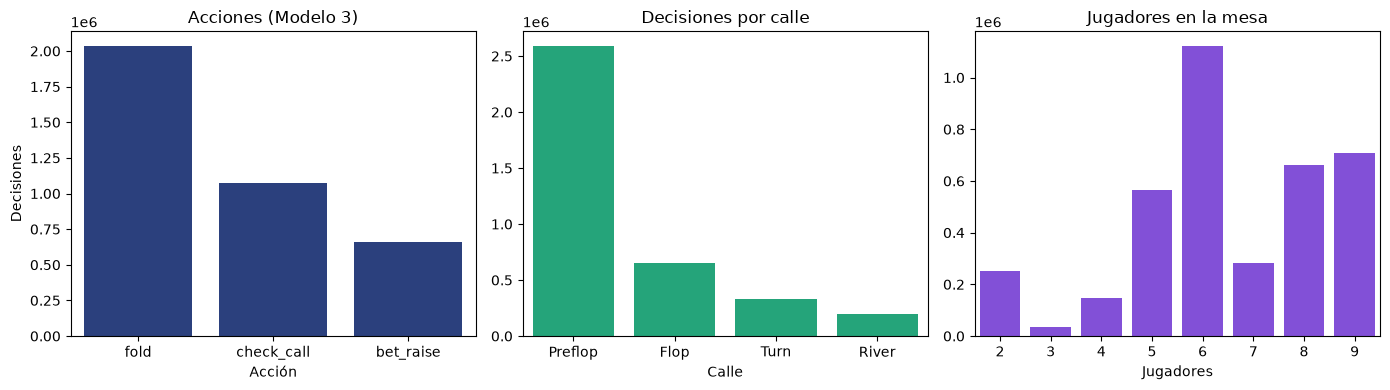

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

nombres_acciones = {0: 'fold', 1: 'check_call', 2: 'bet_raise'}
nombres_calles = {0: 'Preflop', 1: 'Flop', 2: 'Turn', 3: 'River'}

print("🎯 DISTRIBUCIÓN DE ACCIONES POR CONJUNTO:")
tabla = pd.crosstab(df_decisiones['split'], df_decisiones['accion'].map(nombres_acciones), normalize='index') * 100
print(tabla.loc[['train', 'val', 'test']].round(2).to_string())

print("\n🃏 DECISIONES POR CALLE:")
for k, v in df_decisiones['calle'].map(nombres_calles).value_counts().reindex(nombres_calles.values()).items():
    print(f" • {k:<8}: {v:,} ({v / len(df_decisiones) * 100:.2f}%)")

print("\n👥 DECISIONES POR NÚMERO DE JUGADORES EN LA MESA:")
for k, v in df_decisiones['n_jug'].value_counts().sort_index().items():
    print(f" • {k} jugadores: {v:,} ({v / len(df_decisiones) * 100:.1f}%)")

plt.figure(figsize=(14, 4))
plt.subplot(1, 3, 1)
sns.countplot(x=df_decisiones['accion'].map(nombres_acciones), order=['fold', 'check_call', 'bet_raise'], color='#1e3a8a')
plt.title('Acciones (Modelo 3)'); plt.xlabel('Acción'); plt.ylabel('Decisiones')
plt.subplot(1, 3, 2)
sns.countplot(x=df_decisiones['calle'].map(nombres_calles), order=list(nombres_calles.values()), color='#10b981')
plt.title('Decisiones por calle'); plt.xlabel('Calle'); plt.ylabel('')
plt.subplot(1, 3, 3)
sns.countplot(x=df_decisiones['n_jug'], color='#7c3aed')
plt.title('Jugadores en la mesa'); plt.xlabel('Jugadores'); plt.ylabel('')
plt.tight_layout()
os.makedirs('../informe/figuras', exist_ok=True)
plt.savefig('../informe/figuras/modelo3_distribuciones.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
print("=" * 70)
print("  🛡️ VERIFICACIONES ANTI-FUGA DE INFORMACIÓN (Doc. Maestro § 8.5)")
print("=" * 70)

# 1. La prueba que delató al Modelo 1: ¿pot_odds coincide con el bote en TODAS las clases?
enfrenta = df_decisiones[df_decisiones['to_call'] > 0]
coincide = (enfrenta['pot_odds'] - enfrenta['to_call'] / (enfrenta['bote'] + enfrenta['to_call'])).abs() < 0.0015
print("\n1. ¿La foto de la mesa es coherente (antes de actuar) en cada clase?")
print((pd.crosstab(coincide, enfrenta['accion'].map(nombres_acciones), normalize='columns') * 100).round(2).to_string())

# 2. Ninguna mano compartida entre conjuntos
manos = {s: set(df_decisiones.loc[df_decisiones['split'] == s, 'hand_key']) for s in ['train', 'val', 'test']}
print(f"\n2. Manos compartidas Train∩Val: {len(manos['train'] & manos['val'])} | Train∩Test: {len(manos['train'] & manos['test'])} | Val∩Test: {len(manos['val'] & manos['test'])}")

# 3. El orden es cronológico: todo Train ocurre antes que Test
ultimo_train = df_nt.loc[df_nt['split'] == 'train', ['day', 'time']].iloc[-1]
primero_test = df_nt.loc[df_nt['split'] == 'test', ['day', 'time']].iloc[0]
print(f"\n3. Última mano de Train: día {int(ultimo_train['day'])} {ultimo_train['time']} | Primera de Test: día {int(primero_test['day'])} {primero_test['time']}")

# 4. El perfil solo usa el pasado: el historial de cada decisión debe ser EXACTAMENTE
#    el número de manos que ese jugador jugó ANTES de la mano actual
apariciones = df_nt[['hand_key', 'players']].explode('players').rename(columns={'players': 'jugador'})
apariciones['manos_previas'] = apariciones.groupby('jugador').cumcount()
control = df_decisiones[['hand_key', 'jugador', 'pf_manos']].merge(apariciones, on=['hand_key', 'jugador'], how='left')
errores_perfil = (~np.isclose(np.expm1(control['pf_manos']), control['manos_previas'])).sum()
print(f"\n4. Decisiones cuyo perfil incluye la mano actual o manos futuras (debe ser 0): {errores_perfil:,} de {len(control):,}")
del apariciones, control

# 5. La mesa solo muestra cartas ya repartidas
esperado = df_decisiones['calle'].map({0: 0, 1: 3, 2: 4, 3: 5})
print(f"5. Decisiones con cartas comunitarias de más o de menos (debe ser 0): {(df_decisiones['b_n'] != esperado).sum()}")
print("=" * 70)

  🛡️ VERIFICACIONES ANTI-FUGA DE INFORMACIÓN (Doc. Maestro § 8.5)



1. ¿La foto de la mesa es coherente (antes de actuar) en cada clase?


accion  bet_raise  check_call   fold
row_0                               
True        100.0       100.0  100.0



2. Manos compartidas Train∩Val: 0 | Train∩Test: 0 | Val∩Test: 0

3. Última mano de Train: día 17 21:40:40 | Primera de Test: día 18 14:06:12



4. Decisiones cuyo perfil incluye la mano actual o manos futuras (debe ser 0): 0 de 3,773,857
5. Decisiones con cartas comunitarias de más o de menos (debe ser 0): 0


In [8]:
# Separar y guardar los tres conjuntos
print("💾 Guardando conjuntos en data/processed/modelo3/...")
for nombre_split in ['train', 'val', 'test']:
    parte = df_decisiones[df_decisiones['split'] == nombre_split].reset_index(drop=True)
    ruta = os.path.join(processed_dir, f"{nombre_split}.parquet")
    parte.to_parquet(ruta, index=False)
    print(f" • {nombre_split:<5}: {ruta} ➔ {os.path.getsize(ruta) / 1024**2:.1f} MB ({len(parte):,} decisiones)")

print("\n🎉 Fin del Notebook 06: datos del Modelo 3 listos para el entrenamiento.")

💾 Guardando conjuntos en data/processed/modelo3/...


 • train: ../data/processed/modelo3\train.parquet ➔ 103.1 MB (2,584,256 decisiones)


 • val  : ../data/processed/modelo3\val.parquet ➔ 23.8 MB (596,389 decisiones)


 • test : ../data/processed/modelo3\test.parquet ➔ 24.5 MB (593,212 decisiones)

🎉 Fin del Notebook 06: datos del Modelo 3 listos para el entrenamiento.
